# Session 5b: decision trees (is there a large-consolidation threshold?)

**Course link:** Machine Learning Specialization, Course 2 Week 4 (decision trees, entropy, information gain, continuous features, regression trees, tree ensembles: random forests and XGBoost).

**Questions:**
1. Is there a large-consolidation threshold: a ΔCAPB above which growth afterwards is clearly weaker? The thesis uses 1.5 pp as its episode flag; Session 2 hinted at about 3 pp.
2. Do trees predict better than logistic regression?

**Choices made before fitting anything:**
- **Yes/no models** use the same 96 consolidation episodes and the same two targets as Sessions 3–5 (TFP growth from t−1 to t+2 below the training countries' median; or below the median of the same year). Inputs: ΔCAPB and the four lagged controls, with inflation capped at ±30 % and the log of trade openness (Session 5a's rule).
- **Every episode has ΔCAPB ≥ 1.5**, so a tree trained on episodes cannot find a split at 1.5. To test the threshold properly, the **regression tree** (section 6) uses all country-years with data (the Session 1–2 sample) to predict TFP growth itself, against the training-mean baseline. A **ΔCAPB-only stump** (a tree with one split, at least 20 country-years on each side) finds the single best ΔCAPB cut-off.
- **Models:** a single decision tree (entropy); a small random forest (100 trees); a small XGBoost (50 trees, learning rate 0.1); logistic regression from Session 5a side by side (degree 1–3 and λ chosen by cross-validation).
- **Settings** (depth, minimum examples per leaf, and so on) are chosen on the training countries only: 4 groups of training countries, only the left-out group scored.
- **Tree chances are smoothed:** a leaf with k weak episodes out of n says (k + 1) / (n + 2), as if one weak and one not-weak episode were added. Without this, a leaf where every training episode was weak would say 100 %, and log loss punishes a confident miss without limit.
- **The same three tests** (six hidden countries, every country hidden in turn, 500 random splits) and baselines; precision and recall next to accuracy and log loss; error analysis; and the clean placebo with tuning inside every round.

**Runtime:** about 30 minutes on a laptop, most of it the placebo (section 8). In Colab, set `RUN_PLACEBO = False` in the next cell to skip it; the saved results stay in the notebook.

In [1]:
# Load the panel straight from the GitHub repo (no upload needed)
DATA_URL = "https://raw.githubusercontent.com/penelopemichou/austerity-ml/main/data/panel_master.csv"
RUN_PLACEBO = True        # the placebo in section 8 takes most of the runtime

My predictions (fill these in before running; to hide the saved results first, use Edit → Clear all outputs)

1. Where will the first ΔCAPB split fall: at about 1.5 pp, at about 3 pp, or will the trees not split on ΔCAPB at all?
2. Will the trees (single tree, random forest, XGBoost) beat logistic regression with every country hidden in turn?
3. Which input will the single tree split on first (its root)? Will that stay the same when a different country is hidden?
4. Will the regression tree beat "always predict the training mean" for TFP growth?
5. In the placebo, will the real consolidation years stand out for any model?
6. Section 10 compares splits by country, by year and by random rows. Which one will look best, and which one is the most honest?

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from xgboost import XGBClassifier
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", None)
df = pd.read_csv(DATA_URL)

COUNTRY, YEAR, DCAPB, TFP = "country", "year", "dcapb_main", "tfp"
H, CAP = 2, 30
CONTROLS_RAW = ["gdp_growth", "debt_gdp", "inflation", "trade_open"]
CONTROLS = [c + "_lag1" for c in CONTROLS_RAW]
INPUTS = [DCAPB] + CONTROLS
TRADE = "trade_open_lag1"

def add_columns(frame, cap=CAP):
    d = frame.sort_values([COUNTRY, YEAR]).copy()
    d["inflation"] = d["inflation"].clip(-cap, cap)
    d["log_tfp"] = np.log(d[TFP])
    d["growth"] = 100 * (d.groupby(COUNTRY)["log_tfp"].shift(-H) - d.groupby(COUNTRY)["log_tfp"].shift(1))
    for raw, lagged in zip(CONTROLS_RAW, CONTROLS):
        d[lagged] = d.groupby(COUNTRY)[raw].shift(1)
    return d[[COUNTRY, YEAR, DCAPB, "growth"] + CONTROLS].dropna().reset_index(drop=True)

rows_raw = add_columns(df)
rows = rows_raw.copy()
rows[TRADE] = np.log(rows[TRADE])                  # Session 5a's rule: log of trade openness, for every country

TEST_COUNTRIES = ["Belgium", "Greece", "Lithuania", "Malta", "Slovakia", "Spain"]   # same six as Sessions 1-5 (seed 42)
TARGETS = {"Original": False, "Year-adjusted": True}
print(f"{len(rows)} country-years in {rows[COUNTRY].nunique()} countries; "
      f"{int((rows[DCAPB] >= 1.5).sum())} consolidation episodes in {rows.loc[rows[DCAPB] >= 1.5, COUNTRY].nunique()} countries")

669 country-years in 26 countries; 96 consolidation episodes in 24 countries


## 1. Two kinds of sample, two kinds of target

- **Yes/no (classification), on episodes:** `make_split` labels each episode "weak" with cut-offs from the training countries only (per year when year-adjusted), exactly as in Sessions 3–5.
- **A number (regression), on all country-years:** `make_split_reg` uses TFP growth from t−1 to t+2 itself. The year-adjusted version subtracts the training countries' median growth in the same year, so common shocks such as 2009 do not count.

In [3]:
def make_split(hidden, frame=rows, by_year=False):
    tr_all = frame[~frame[COUNTRY].isin(hidden)]
    median = tr_all.groupby(YEAR)["growth"].median() if by_year else tr_all["growth"].median()
    tr = tr_all[tr_all[DCAPB] >= 1.5].copy()
    te = frame[frame[COUNTRY].isin(hidden) & (frame[DCAPB] >= 1.5)].copy()
    for d in (tr, te):
        d["weak"] = (d["growth"] < (d[YEAR].map(median) if by_year else median)).astype(float)
    return tr, te

def make_split_reg(hidden, frame=rows, by_year=False):
    tr = frame[~frame[COUNTRY].isin(hidden)].copy()
    te = frame[frame[COUNTRY].isin(hidden)].copy()
    year_median = tr.groupby(YEAR)["growth"].median()
    for d in (tr, te):
        d["y"] = d["growth"] - d[YEAR].map(year_median) if by_year else d["growth"]
    return tr, te

TASKS = {"class": (make_split, "weak"), "reg": (make_split_reg, "y")}

## 2. The models

**Course link:** Week 4. A decision tree asks one yes/no question at a time ("is debt above 60 %?"). At each node it picks the input and cut-off with the largest **information gain**: the biggest drop in **entropy**, the measure of how mixed weak and not-weak episodes are. For a number such as ΔCAPB, it tries every cut-off between two observed values.

- **Decision tree:** `max_depth` (how many questions in a row) and `min_samples_leaf` (smallest group allowed at the end) are the settings that keep it from fitting noise.
- **Random forest:** many trees, each trained on a random resample of the training episodes (sampling with replacement) and choosing among a random subset of inputs at each node. Averaging them is steadier than one tree.
- **XGBoost:** trees built one after another, each concentrating on the episodes the earlier ones got wrong.
- **Logistic regression:** Session 5a's model (polynomial degree 1–3, λ 0.01–1000), side by side.

A tree only uses the *order* of an input's values, so the log of trade openness changes nothing for trees. It also means a tree cannot extrapolate: an economy more open than any it has seen simply lands in the most open group.

In [4]:
LAMBDAS = [0.01, 0.1, 1, 3, 10, 30, 100, 300, 1000]
GRIDS = {
    "logistic regression": [(d, l) for d in (1, 2, 3) for l in LAMBDAS],
    "decision tree": [(depth, leaf) for depth in (1, 2, 3, 4) for leaf in (5, 10, 15, 20)],
    "random forest": [(depth, leaf) for depth in (2, 3, 4) for leaf in (5, 10, 20)],
    "XGBoost": [(depth, mcw) for depth in (1, 2, 3) for mcw in (1, 5)],
    "regression tree": [(depth, leaf) for depth in (1, 2, 3, 4) for leaf in (10, 20, 40)],
    "linear regression": [None],
    "ΔCAPB stump": [None],
}
CLASSIFIERS = ["logistic regression", "decision tree", "random forest", "XGBoost"]
REGRESSORS = ["linear regression", "regression tree", "ΔCAPB stump"]

def poly_features(tr, te, degree):
    mu, sd = tr[INPUTS].mean(), tr[INPUTS].std(ddof=0).replace(0, 1)
    poly = PolynomialFeatures(degree, include_bias=False)
    F_tr, F_te = poly.fit_transform((tr[INPUTS] - mu) / sd), poly.transform((te[INPUTS] - mu) / sd)
    m, s = F_tr.mean(axis=0), F_tr.std(axis=0)
    s[s == 0] = 1
    return (F_tr - m) / s, (F_te - m) / s

def smoothed_leaf_chance(tree, X_tr, y_tr, X_te):
    # (weak episodes in the leaf + 1) / (episodes in the leaf + 2)
    counts = pd.DataFrame({"leaf": tree.apply(X_tr), "y": y_tr}).groupby("leaf")["y"].agg(["sum", "count"])
    return ((counts["sum"] + 1) / (counts["count"] + 2)).reindex(tree.apply(X_te)).to_numpy()

def build(kind, setting):
    if kind == "decision tree":
        return DecisionTreeClassifier(criterion="entropy", max_depth=setting[0], min_samples_leaf=setting[1], random_state=0)
    if kind == "random forest":
        return RandomForestClassifier(n_estimators=100, criterion="entropy", max_depth=setting[0], min_samples_leaf=setting[1],
                                      max_features="sqrt", random_state=0, n_jobs=1)
    if kind == "XGBoost":
        return XGBClassifier(n_estimators=50, learning_rate=0.1, max_depth=setting[0], min_child_weight=setting[1],
                             random_state=0, n_jobs=1, eval_metric="logloss")
    if kind == "regression tree":
        return DecisionTreeRegressor(max_depth=setting[0], min_samples_leaf=setting[1], random_state=0)
    if kind == "ΔCAPB stump":
        return DecisionTreeRegressor(max_depth=1, min_samples_leaf=20, random_state=0)
    if kind == "linear regression":
        return LinearRegression()

def fit_predict(kind, setting, tr, te):
    if kind == "logistic regression":
        F_tr, F_te = poly_features(tr, te, setting[0])
        return LogisticRegression(C=1 / setting[1], max_iter=20000).fit(F_tr, tr["weak"]).predict_proba(F_te)[:, 1]
    if kind in REGRESSORS:
        cols = [DCAPB] if kind == "ΔCAPB stump" else INPUTS
        return build(kind, setting).fit(tr[cols].to_numpy(), tr["y"].to_numpy()).predict(te[cols].to_numpy())
    X_tr, X_te, y = tr[INPUTS].to_numpy(), te[INPUTS].to_numpy(), tr["weak"].to_numpy()
    model = build(kind, setting).fit(X_tr, y)
    if kind == "decision tree":
        return smoothed_leaf_chance(model, X_tr, y, X_te)
    return model.predict_proba(X_te)[:, 1]

def log_loss(p, y):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def mse(p, y):
    return np.mean((np.asarray(p) - np.asarray(y)) ** 2)

def task_of(kind):
    return "reg" if kind in REGRESSORS else "class"

## 3. Choosing the settings on the training countries only

As in Sessions 4–5: the training countries are split into 4 groups; each setting is trained on 3 groups and scored on the 4th (log loss for yes/no, mean squared error for TFP growth). Only the left-out training countries are ever scored.

In [5]:
def cv_groups(countries, k=4):
    c = sorted(countries)
    np.random.default_rng(0).shuffle(c)
    return [c[i::k] for i in range(k)]

def cv_score(kind, setting, hidden, frame, by_year):
    split, target = TASKS[task_of(kind)]
    train_c = [c for c in frame[COUNTRY].unique() if c not in hidden]
    ys, ps = [], []
    for g in cv_groups(train_c):
        tr, te = split(list(hidden) + g, frame, by_year)
        te = te[te[COUNTRY].isin(g)]                       # score only the left-out training countries
        if len(te):
            ps.append(fit_predict(kind, setting, tr, te)); ys.append(te[target].to_numpy())
    loss = mse if task_of(kind) == "reg" else log_loss
    return loss(np.concatenate(ps), np.concatenate(ys))

def choose(kind, hidden, frame=rows, by_year=False):
    grid = GRIDS[kind]
    if len(grid) == 1:
        return grid[0]
    scores_ = {s: cv_score(kind, s, hidden, frame, by_year) for s in grid}
    return min(scores_, key=scores_.get)

chosen = {(t, k): choose(k, TEST_COUNTRIES, by_year=b) for t, b in TARGETS.items() for k in CLASSIFIERS + REGRESSORS}
pd.Series({f"{t}, {k}": str(s) for (t, k), s in chosen.items()}, name="chosen on the 20 training countries").to_frame()

,chosen on the 20 training countries
"Original, logistic regression","(2, 30)"
"Original, decision tree","(2, 15)"
"Original, random forest","(2, 10)"
"Original, XGBoost","(1, 5)"
"Original, linear regression",None
"Original, regression tree","(1, 20)"
"Original, ΔCAPB stump",None
"Year-adjusted, logistic regression","(2, 10)"
"Year-adjusted, decision tree","(1, 20)"
"Year-adjusted, random forest","(2, 10)"


## 4. The trees themselves: what does the single tree split on?

The trees chosen in section 3, trained on the 20 training countries. Each box shows the question, the entropy, the number of episodes and how many are not weak / weak.

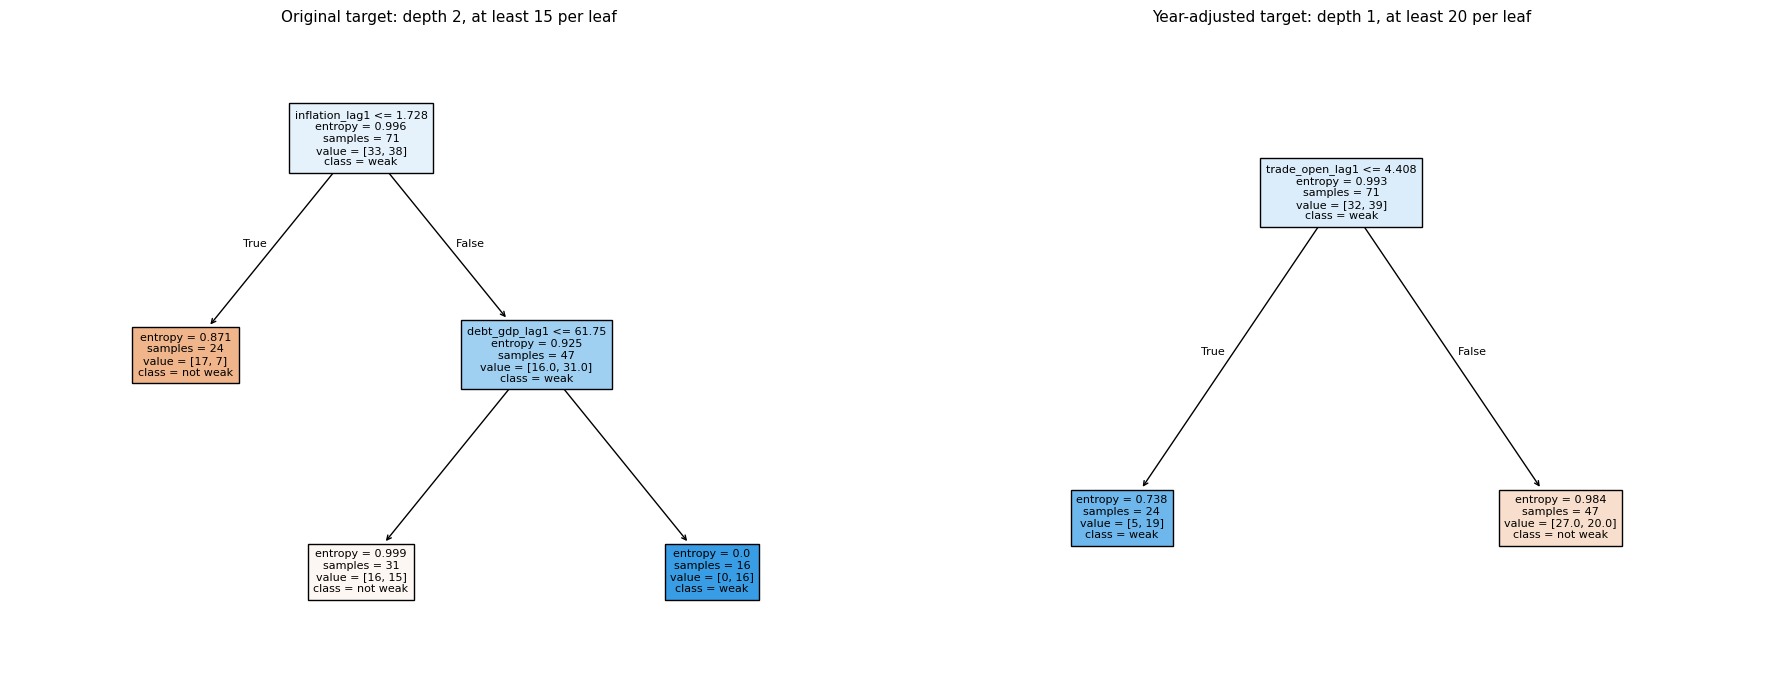

Original: root split ('inflation_lag1', 1.727988362312317); first ΔCAPB split (depth, cut-off): None
Year-adjusted: root split ('trade_open_lag1', 4.407683610916138); first ΔCAPB split (depth, cut-off): None
(trade_open_lag1 is the log of trade openness: exp() of a cut-off gives % of GDP)


In [6]:
def first_dcapb_split(tree, names):
    # the shallowest node that splits on ΔCAPB, as (depth, cut-off); None if the tree never uses ΔCAPB
    t, todo = tree.tree_, [(0, 0)]
    while todo:
        node, depth = todo.pop(0)
        if t.children_left[node] == -1:
            continue
        if names[t.feature[node]] == DCAPB:
            return depth, float(t.threshold[node])
        todo += [(t.children_left[node], depth + 1), (t.children_right[node], depth + 1)]
    return None

def root_split(tree, names):
    t = tree.tree_
    return (names[t.feature[0]], float(t.threshold[0])) if t.children_left[0] != -1 else ("no split", np.nan)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
trees_six = {}
for ax, (t, b) in zip(axes, TARGETS.items()):
    tr, _ = make_split(TEST_COUNTRIES, by_year=b)
    tree = build("decision tree", chosen[(t, "decision tree")]).fit(tr[INPUTS].to_numpy(), tr["weak"].to_numpy())
    trees_six[t] = tree
    plot_tree(tree, feature_names=INPUTS, class_names=["not weak", "weak"], filled=True, impurity=True, fontsize=8, ax=ax)
    ax.set_title(f"{t} target: depth {chosen[(t, 'decision tree')][0]}, at least {chosen[(t, 'decision tree')][1]} per leaf", fontsize=11)
plt.tight_layout(); plt.show()
for t, tree in trees_six.items():
    print(f"{t}: root split {root_split(tree, INPUTS)}; first ΔCAPB split (depth, cut-off): {first_dcapb_split(tree, INPUTS)}")
print("(trade_open_lag1 is the log of trade openness: exp() of a cut-off gives % of GDP)")

## 5. The three tests for the yes/no models

Six hidden countries with the section 3 settings; every country hidden in turn with the settings chosen again inside every round; 500 random splits with the section 3 settings (slightly optimistic, as before).

In [7]:
def scores(y, p, prior):
    return {"log loss": log_loss(p, y), "baseline log loss": log_loss(np.full(len(y), prior), y),
            "accuracy": np.mean((p >= 0.5) == y), "baseline accuracy": np.mean(float(prior >= 0.5) == y)}

def loco(kind, frame=rows, by_year=False, fixed=None):
    # every country hidden in turn; settings chosen again in each round unless fixed
    task = task_of(kind)
    split, target = TASKS[task]
    countries = frame.loc[frame[DCAPB] >= 1.5, COUNTRY].unique() if task == "class" else frame[COUNTRY].unique()
    parts, per = [], []
    for c in countries:
        setting = fixed if fixed is not None else choose(kind, [c], frame, by_year)
        tr, te = split([c], frame, by_year)
        part = te[[COUNTRY, YEAR, DCAPB, target]].copy()
        part["pred"] = fit_predict(kind, setting, tr, te)
        part["guess"] = tr[target].mean()
        parts.append(part)
        per.append({"country": c, "chosen": setting})
    return pd.concat(parts), pd.DataFrame(per).set_index("country")

def summarise_class(pr):
    y, p, g = pr["weak"].to_numpy(), pr["pred"].to_numpy(), pr["guess"].to_numpy()
    by_c = pr.groupby(COUNTRY).apply(lambda d: log_loss(d["pred"].to_numpy(), d["weak"].to_numpy()) < log_loss(d["guess"].to_numpy(), d["weak"].to_numpy()))
    return {"log loss": log_loss(p, y), "baseline": log_loss(g, y), "gain %": 100 * (1 - log_loss(p, y) / log_loss(g, y)),
            "accuracy": np.mean((p >= 0.5) == y), "baseline accuracy": np.mean((g >= 0.5) == y), "won": int(by_c.sum()), "countries": len(by_c)}

def random_splits(kind, setting, by_year, n=500):
    task = task_of(kind)
    split, target = TASKS[task]
    countries = rows.loc[rows[DCAPB] >= 1.5, COUNTRY].unique() if task == "class" else rows[COUNTRY].unique()
    rng = np.random.default_rng(0)
    gains = []
    for _ in range(n):
        tr, te = split(rng.choice(countries, size=6, replace=False), rows, by_year)
        p, y, g = fit_predict(kind, setting, tr, te), te[target].to_numpy(), np.full(len(te), tr[target].mean())
        gains.append(100 * (1 - (mse(p, y) / mse(g, y) if task == "reg" else log_loss(p, y) / log_loss(g, y))))
    return np.array(gains)

loo_pred, loo_chosen, results = {}, {}, {}
for t, b in TARGETS.items():
    tr6, te6 = make_split(TEST_COUNTRIES, by_year=b)
    for k in CLASSIFIERS:
        s6 = scores(te6["weak"].to_numpy(), fit_predict(k, chosen[(t, k)], tr6, te6), tr6["weak"].mean())
        loo_pred[(t, k)], loo_chosen[(t, k)] = loco(k, by_year=b)
        lo = summarise_class(loo_pred[(t, k)])
        gains = random_splits(k, chosen[(t, k)], b)
        results[(t, k)] = {
            "six hidden: log loss vs baseline": f"{s6['log loss']:.3f} vs {s6['baseline log loss']:.3f}",
            "six hidden: accuracy vs baseline": f"{s6['accuracy']:.0%} vs {s6['baseline accuracy']:.0%}",
            "each hidden in turn: log loss vs baseline": f"{lo['log loss']:.3f} vs {lo['baseline']:.3f} ({lo['gain %']:+.1f} %)",
            "each hidden in turn: accuracy vs baseline": f"{lo['accuracy']:.1%} vs {lo['baseline accuracy']:.1%}",
            "countries won": f"{lo['won']} of {lo['countries']}",
            "500 splits: log loss better": f"{np.mean(gains > 0):.0%} (median {np.median(gains):+.1f} %)"}
pd.DataFrame(results)

Original                                                                                       Year-adjusted  \
                                               logistic regression            decision tree            random forest                  XGBoost      logistic regression   
six hidden: log loss vs baseline                    0.620 vs 0.710           0.758 vs 0.710           0.623 vs 0.710           0.701 vs 0.710           0.594 vs 0.718   
six hidden: accuracy vs baseline                        72% vs 40%               68% vs 40%               60% vs 40%               48% vs 40%               60% vs 40%   
each hidden in turn: log loss vs baseline  0.682 vs 0.694 (+1.7 %)  0.745 vs 0.694 (-7.4 %)  0.648 vs 0.694 (+6.6 %)  0.637 vs 0.694 (+8.3 %)  0.686 vs 0.700 (+1.9 %)   
each hidden in turn: accuracy vs baseline           62.5% vs 49.0%           50.0% vs 49.0%           62.5% vs 49.0%           65.6% vs 49.0%           61.5% vs 42.7%   
countries won                                             16 of 24                  9 of 24                 16 of 24                 16 of 24                 13 of 24   
500 splits: log loss better                    84% (median +6.8 %)      35% (median -5.0 %)      78% (median +6.3 %)      63% (median +4.8 %)      64% (median +3.3 %)   

                                                                                                                      
                                                     decision tree            random forest                  XGBoost  
six hidden: log loss vs baseline                    0.571 vs 0.718           0.613 vs 0.718           0.589 vs 0.718  
six hidden: accuracy vs baseline                        80% vs 40%               76% vs 40%               72% vs 40%  
each hidden in turn: log loss vs baseline  0.751 vs 0.700 (-7.4 %)  0.678 vs 0.700 (+3.0 %)  0.694 vs 0.700 (+0.8 %)  
each hidden in turn: accuracy vs baseline           54.2% vs 42.7%           57.3% vs 42.7%           64.6% vs 42.7%  
countries won                                              9 of 24                 15 of 24                  9 of 24  
500 splits: log loss better                    54% (median +1.1 %)      72% (median +4.8 %)      58% (median +2.4 %)

In [8]:
# Precision and recall ("weak" = positive), from the every-country-hidden-in-turn predictions
def class_metrics(y, pred, positive):
    tp = int(((pred == positive) & (y == positive)).sum()); fp = int(((pred == positive) & (y != positive)).sum())
    fn = int(((pred != positive) & (y == positive)).sum())
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    return precision, recall, (2 * precision * recall / (precision + recall) if precision + recall > 0 else np.nan)

for t in TARGETS:
    table = {}
    for who in CLASSIFIERS + ["simple guess"]:
        pr = loo_pred[(t, "logistic regression" if who == "simple guess" else who)]
        y = pr["weak"].to_numpy()
        p = pr["guess" if who == "simple guess" else "pred"].to_numpy()
        pred = (p >= 0.5).astype(float)
        pw, rw, fw = class_metrics(y, pred, 1.0); pn, rn, fn_ = class_metrics(y, pred, 0.0)
        table[who] = {"log loss": log_loss(p, y), "accuracy": np.mean(pred == y), "precision (weak)": pw, "recall (weak)": rw,
                      "F1 (weak)": fw, "precision (not weak)": pn, "recall (not weak)": rn, "says weak": int(pred.sum())}
    print(f"{t} target"); print(pd.DataFrame(table).round(3).to_string()); print()

Original target
                      logistic regression  decision tree  random forest  XGBoost  simple guess
log loss                            0.682          0.745          0.648    0.637         0.694
accuracy                            0.625          0.500          0.625    0.656         0.490
precision (weak)                    0.710          0.510          0.638    0.674         0.500
recall (weak)                       0.449          0.531          0.612    0.633         0.898
F1 (weak)                           0.550          0.520          0.625    0.653         0.642
precision (not weak)                0.585          0.489          0.612    0.640         0.375
recall (not weak)                   0.809          0.468          0.638    0.681         0.064
says weak                          31.000         51.000         47.000   46.000        88.000

Year-adjusted target
                      logistic regression  decision tree  random forest  XGBoost  simple guess
log loss    

## 6. A number instead of yes/no: regression trees for TFP growth, on all country-years

Here the sample is every country-year with data, consolidation or not, so ΔCAPB runs from large loosenings to large tightenings and a tree can put a cut-off anywhere, including 1.5 pp. The baseline is the training-mean (Sessions 1–2). Linear regression on the same inputs runs side by side. The **ΔCAPB stump** uses ΔCAPB alone with a single split: its cut-off is the one ΔCAPB value that best separates growth afterwards.

In [9]:
reg_pred, reg_chosen, reg_results = {}, {}, {}
for t, b in TARGETS.items():
    tr6, te6 = make_split_reg(TEST_COUNTRIES, by_year=b)
    for k in REGRESSORS:
        p6 = fit_predict(k, chosen[(t, k)], tr6, te6)
        m6, g6 = mse(p6, te6["y"]), mse(np.full(len(te6), tr6["y"].mean()), te6["y"])
        reg_pred[(t, k)], reg_chosen[(t, k)] = loco(k, by_year=b)
        pr = reg_pred[(t, k)]
        by_c = pr.groupby(COUNTRY).apply(lambda d: mse(d["pred"], d["y"]) < mse(d["guess"], d["y"]))
        m, g = mse(pr["pred"], pr["y"]), mse(pr["guess"], pr["y"])
        gains = random_splits(k, chosen[(t, k)], b)
        reg_results[(t, k)] = {
            "chosen (depth, leaf)": str(chosen[(t, k)]),
            "six hidden: squared error vs mean": f"{m6:.1f} vs {g6:.1f} ({100 * (1 - m6 / g6):+.1f} %)",
            "each hidden in turn: squared error vs mean": f"{m:.1f} vs {g:.1f} ({100 * (1 - m / g):+.1f} %)",
            "countries won": f"{int(by_c.sum())} of {len(by_c)}",
            "500 splits: better than the mean": f"{np.mean(gains > 0):.0%} (median {np.median(gains):+.1f} %)"}
pd.DataFrame(reg_results)

Original                                                          Year-adjusted                         \
                                                linear regression         regression tree            ΔCAPB stump       linear regression        regression tree   
chosen (depth, leaf)                                         None                 (1, 20)                   None                    None                (2, 10)   
six hidden: squared error vs mean           28.5 vs 30.7 (+7.4 %)   30.4 vs 30.7 (+1.1 %)  31.2 vs 30.7 (-1.6 %)  22.1 vs 25.9 (+14.7 %)  27.1 vs 25.9 (-4.8 %)   
each hidden in turn: squared error vs mean  30.3 vs 29.5 (-2.7 %)  33.3 vs 29.5 (-12.9 %)  29.3 vs 29.5 (+0.7 %)   23.7 vs 23.0 (-2.9 %)  22.7 vs 23.0 (+1.4 %)   
countries won                                            15 of 26                12 of 26               13 of 26                17 of 26               15 of 26   
500 splits: better than the mean              47% (median -1.4 %)     33% (median -3.5 %)    51% (median +0.0 %)     51% (median +0.4 %)    36% (median -5.2 %)   

                                                                   
                                                      ΔCAPB stump  
chosen (depth, leaf)                                         None  
six hidden: squared error vs mean           25.6 vs 25.9 (+0.9 %)  
each hidden in turn: squared error vs mean  23.4 vs 23.0 (-1.6 %)  
countries won                                             9 of 26  
500 splits: better than the mean              32% (median -1.2 %)

## 7. Is there a large-consolidation threshold? Where the trees cut ΔCAPB

For each tree: its first ΔCAPB cut-off on the six-hidden training countries, and how the root split and the ΔCAPB cut-off move across the rounds where each country is hidden in turn (each round refits with the settings it chose). For the stump, the average TFP growth on each side of its cut-off, on all country-years.

In [10]:
def round_splits(kind, by_year):
    task = task_of(kind)
    split, target = TASKS[task]
    out = []
    for c, setting in (loo_chosen if task == "class" else reg_chosen)[(t_name[by_year], kind)]["chosen"].items():
        tr, _ = split([c], rows, by_year)
        cols = [DCAPB] if kind == "ΔCAPB stump" else INPUTS
        tree = build(kind, setting).fit(tr[cols].to_numpy(), tr[target].to_numpy())
        root = root_split(tree, cols)
        first = first_dcapb_split(tree, cols)
        out.append({"hidden": c, "root input": root[0], "root cut-off": root[1],
                    "first ΔCAPB cut-off": first[1] if first else np.nan, "at depth": first[0] if first else np.nan})
    return pd.DataFrame(out)

t_name = {b: t for t, b in TARGETS.items()}
summary = {}
for t, b in TARGETS.items():
    for k in ["decision tree", "regression tree", "ΔCAPB stump"]:
        r = round_splits(k, b)
        cut = r["first ΔCAPB cut-off"].dropna()
        summary[(t, k)] = {
            "root input (rounds)": ", ".join(f"{n} ×{v}" for n, v in r["root input"].value_counts().items()),
            "rounds that split on ΔCAPB": f"{len(cut)} of {len(r)}",
            "ΔCAPB cut-off: median (min to max)": f"{cut.median():.2f} ({cut.min():.2f} to {cut.max():.2f})" if len(cut) else "never",
            "ΔCAPB cut-off: most common": f"{cut.round(2).mode().iloc[0]:.2f} ×{int((cut.round(2) == cut.round(2).mode().iloc[0]).sum())}" if len(cut) else "never"}
print(pd.DataFrame(summary).T.to_string())
print()
for t, b in TARGETS.items():
    tr_all, _ = make_split_reg([], by_year=b)
    stump = build("ΔCAPB stump", None).fit(tr_all[[DCAPB]].to_numpy(), tr_all["y"].to_numpy())
    cut = stump.tree_.threshold[0]
    below, above = tr_all[tr_all[DCAPB] <= cut], tr_all[tr_all[DCAPB] > cut]
    print(f"{t}, stump on all {len(tr_all)} country-years: cut-off ΔCAPB = {cut:.2f} pp; average growth "
          f"{below['y'].mean():+.2f} % below ({len(below)} country-years) vs {above['y'].mean():+.2f} % above ({len(above)})")
    for c0 in (1.5, 3.0):
        print(f"    for comparison, at {c0} pp: {tr_all.loc[tr_all[DCAPB] < c0, 'y'].mean():+.2f} % below vs {tr_all.loc[tr_all[DCAPB] >= c0, 'y'].mean():+.2f} % at or above ({int((tr_all[DCAPB] >= c0).sum())} country-years)")

                                                                     root input (rounds) rounds that split on ΔCAPB ΔCAPB cut-off: median (min to max) ΔCAPB cut-off: most common
Original      decision tree    trade_open_lag1 ×14, gdp_growth_lag1 ×7, debt_gdp_lag1 ×3                    1 of 24                3.45 (3.45 to 3.45)                    3.45 ×1
              regression tree                     inflation_lag1 ×25, gdp_growth_lag1 ×1                    3 of 26                0.45 (0.45 to 0.45)                    0.45 ×3
              ΔCAPB stump                                                 dcapb_main ×26                   26 of 26                3.45 (3.35 to 3.45)                   3.45 ×25
Year-adjusted decision tree                        trade_open_lag1 ×22, debt_gdp_lag1 ×2                    0 of 24                              never                      never
              regression tree  gdp_growth_lag1 ×22, debt_gdp_lag1 ×3, trade_open_lag1 ×1                   21 

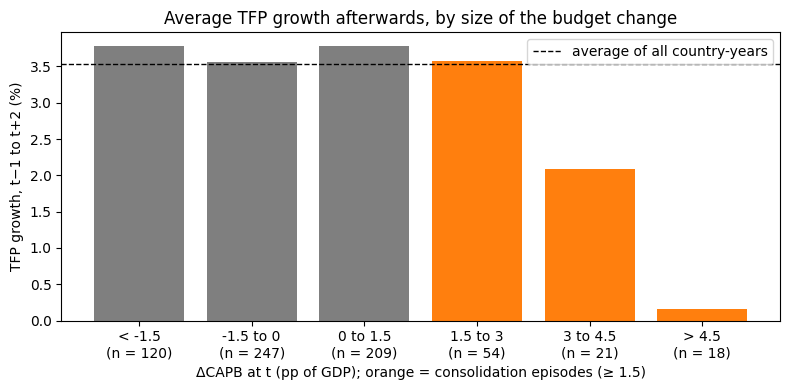

In [11]:
# Average growth by ΔCAPB band, all country-years (original target), with the stump's cut-off
tr_all, _ = make_split_reg([])
bands = pd.cut(tr_all[DCAPB], [-30, -1.5, 0, 1.5, 3, 4.5, 30], labels=["< -1.5", "-1.5 to 0", "0 to 1.5", "1.5 to 3", "3 to 4.5", "> 4.5"])
band = tr_all.groupby(bands, observed=True)["y"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(len(band)), band["mean"], color=["tab:grey"] * 3 + ["tab:orange"] * 3)
ax.set_xticks(range(len(band))); ax.set_xticklabels([f"{i}\n(n = {n})" for i, n in zip(band.index, band["count"])])
ax.axhline(tr_all["y"].mean(), color="black", lw=1, ls="--", label="average of all country-years")
ax.set_xlabel("ΔCAPB at t (pp of GDP); orange = consolidation episodes (≥ 1.5)"); ax.set_ylabel("TFP growth, t−1 to t+2 (%)")
ax.set_title("Average TFP growth afterwards, by size of the budget change"); ax.legend(); plt.tight_layout(); plt.show()

## 8. Placebo test (clean): settings chosen again inside every round

Within each country, the ΔCAPB values are shuffled across years (each country keeps its number of episodes and their sizes), and every model is rerun with every country hidden in turn, with its settings chosen again inside every round, exactly as in section 5. 100 shuffles per model and target, run in parallel. If the real episodes do not beat most shuffles, a model's gain is not about the consolidations.

In [12]:
def shuffle_episodes(frame, seed):
    rng = np.random.default_rng(seed)
    d = frame.copy()
    d[DCAPB] = d.groupby(COUNTRY)[DCAPB].transform(lambda s: rng.permutation(s.to_numpy()))
    return d

def placebo_gain(kind, frame, by_year):
    pr, _ = loco(kind, frame, by_year)
    if task_of(kind) == "reg":
        return 100 * (1 - mse(pr["pred"], pr["y"]) / mse(pr["guess"], pr["y"]))
    return summarise_class(pr)["gain %"]

N_PLACEBO = 100
placebo = {}
if RUN_PLACEBO:
    for t, b in TARGETS.items():
        for k in CLASSIFIERS + ["regression tree", "linear regression"]:
            real = placebo_gain(k, rows, b)
            fake = np.array(Parallel(n_jobs=-1)(delayed(placebo_gain)(k, shuffle_episodes(rows, s), b) for s in range(N_PLACEBO)))
            placebo[(t, k)] = (real, fake)
    print(pd.DataFrame({key: {"real: gain vs baseline (%)": f"{real:+.1f}",
                              "shuffled: median (middle 90 %)": f"{np.median(fake):+.1f} ({np.percentile(fake, 5):+.1f} to {np.percentile(fake, 95):+.1f})",
                              "shuffles at least as good": f"{np.mean(fake >= real):.0%}"}
                        for key, (real, fake) in placebo.items()}).T.to_string())
    print("(gain = lower log loss for the yes/no models, lower squared error for the regressions)")

                                  real: gain vs baseline (%) shuffled: median (middle 90 %) shuffles at least as good
Original      logistic regression                       +1.7           -3.8 (-20.8 to +6.2)                       16%
              decision tree                             -7.4           -7.5 (-21.4 to +5.9)                       50%
              random forest                             +6.6            +1.1 (-3.1 to +8.6)                       14%
              XGBoost                                   +8.3           -1.2 (-13.1 to +8.6)                        7%
              regression tree                          -12.9          -12.9 (-13.4 to -6.9)                       52%
              linear regression                         -2.7            -3.1 (-3.7 to -2.5)                       12%
Year-adjusted logistic regression                       +1.9           -3.2 (-14.9 to +6.9)                       21%
              decision tree                             

## 9. Error analysis: which episodes does each model get most wrong?

From the every-country-hidden-in-turn predictions in section 5: each model's worst episodes, the countries adding the most loss beyond the simple guess, and the loss by period.

In [13]:
def per_episode_loss(p, y):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

for t in TARGETS:
    rows_out = {}
    for k in CLASSIFIERS:
        pr = loo_pred[(t, k)].copy()
        pr["loss"] = per_episode_loss(pr["pred"], pr["weak"]); pr["guess loss"] = per_episode_loss(pr["guess"], pr["weak"])
        pr["period"] = pd.cut(pr[YEAR], [1990, 2007, 2013, 2030], labels=["1997-2007", "2008-2013", "2014-2022"])
        worst = pr.sort_values("loss", ascending=False).head(4)
        countries = (pr["loss"] - pr["guess loss"]).groupby(pr[COUNTRY]).sum().sort_values(ascending=False).head(3)
        period = pr.groupby("period", observed=True)[["loss", "guess loss"]].mean()
        rows_out[k] = {"worst episodes (chance of weak given; actual)": "; ".join(f"{r[COUNTRY]} {r[YEAR]} ({r['pred']:.2f}; {'weak' if r['weak'] else 'not weak'})" for _, r in worst.iterrows()),
                       "countries adding the most loss": ", ".join(f"{c} {v:+.2f}" for c, v in countries.items()),
                       **{f"{p}: loss vs guess": f"{period.loc[p, 'loss']:.3f} vs {period.loc[p, 'guess loss']:.3f}" for p in period.index}}
    print(f"===== {t} target ====="); print(pd.DataFrame(rows_out).T.to_string()); print()

pr = reg_pred[("Original", "regression tree")].copy()
pr["sq error"] = (pr["pred"] - pr["y"]) ** 2; pr["guess sq error"] = (pr["guess"] - pr["y"]) ** 2
print("Regression tree (original target): the 6 country-years with the largest squared error")
print(pr.sort_values("sq error", ascending=False).head(6)[[COUNTRY, YEAR, DCAPB, "y", "pred", "guess"]].round(1).to_string(index=False))

===== Original target =====
                                                                                                 worst episodes (chance of weak given; actual)                  countries adding the most loss 1997-2007: loss vs guess 2008-2013: loss vs guess 2014-2022: loss vs guess
logistic regression     Luxembourg 2021 (0.13; weak); Luxembourg 2000 (0.15; weak); Luxembourg 2018 (0.16; weak); Greece 2005 (0.84; not weak)  Luxembourg +4.40, Hungary +0.59, Estonia +0.26           0.689 vs 0.695           0.619 vs 0.692           0.744 vs 0.694
decision tree        Romania 2013 (0.89; not weak); Finland 1998 (0.88; not weak); Finland 2000 (0.88; not weak); Latvia 2000 (0.86; not weak)   Finland +2.41, Luxembourg +1.97, Latvia +1.25           0.860 vs 0.695           0.643 vs 0.692           0.728 vs 0.694
random forest                   Greece 2005 (0.84; not weak); Luxembourg 2000 (0.22; weak); Latvia 2022 (0.27; weak); Sweden 2022 (0.27; weak)   Luxembourg +1.72, Poland +0.7

## 10. Optional: folds grouped by country, by year, or by random rows

The LinkedIn question: does grouping the held-out data by country or by year matter more? The same two yes/no models (logistic regression and the single tree, settings fixed at the section 3 choice, original target) are scored four ways:
- **Random rows:** episodes are split at random, ignoring country and year. Overlapping target windows and shared years leak information, so this should look too good.
- **By country:** 6 groups of whole countries held out (as in all sessions).
- **By year:** blocks of years held out, and training uses only years at least 3 years away, so no target window overlaps the test block.
- **By country and year:** a group of countries *and* a block of years held out together.

The "weak" cut-off always comes from the training rows only. The year-adjusted target is left out here, because it needs other countries in the same year, which year blocks remove.

In [14]:
BLOCKS = [(1997, 2001), (2002, 2006), (2007, 2010), (2011, 2014), (2015, 2018), (2019, 2022)]
episodes_all = rows[rows[DCAPB] >= 1.5]
country_groups = cv_groups(list(episodes_all[COUNTRY].unique()), k=6)

def score_scheme(kind, setting, folds):
    ys, ps, gs = [], [], []
    for train_rows, test_idx in folds:
        test = rows.loc[test_idx]
        if len(test) == 0:
            continue
        median = train_rows["growth"].median()
        tr = train_rows[train_rows[DCAPB] >= 1.5].copy(); te = test.copy()
        tr["weak"] = (tr["growth"] < median).astype(float); te["weak"] = (te["growth"] < median).astype(float)
        ps.append(fit_predict(kind, setting, tr, te)); ys.append(te["weak"].to_numpy()); gs.append(np.full(len(te), tr["weak"].mean()))
    y, p, g = map(np.concatenate, (ys, ps, gs))
    return {"log loss": log_loss(p, y), "baseline": log_loss(g, y), "gain %": 100 * (1 - log_loss(p, y) / log_loss(g, y)),
            "accuracy": np.mean((p >= 0.5) == y), "baseline accuracy": np.mean((g >= 0.5) == y), "held-out episodes": len(y)}

def folds_for(scheme):
    folds = []
    if scheme == "random rows":
        order = np.random.default_rng(0).permutation(episodes_all.index)
        for i in range(6):
            test_idx = order[i::6]
            folds.append((rows.drop(index=test_idx), test_idx))
    if scheme == "by country":
        for g in country_groups:
            folds.append((rows[~rows[COUNTRY].isin(g)], episodes_all.index[episodes_all[COUNTRY].isin(g)]))
    if scheme in ("by year", "by country and year"):
        for a, z in BLOCKS:
            far = (rows[YEAR] < a - 3) | (rows[YEAR] > z + 3)          # no overlapping target windows
            in_block = episodes_all[(episodes_all[YEAR] >= a) & (episodes_all[YEAR] <= z)]
            if scheme == "by year":
                folds.append((rows[far], in_block.index))
            else:
                for g in country_groups:
                    folds.append((rows[far & ~rows[COUNTRY].isin(g)], in_block.index[in_block[COUNTRY].isin(g)]))
    return folds

grouping = {}
for k in ["logistic regression", "decision tree"]:
    for scheme in ["random rows", "by country", "by year", "by country and year"]:
        r = score_scheme(k, chosen[("Original", k)], folds_for(scheme))
        grouping[(k, scheme)] = {"log loss vs baseline": f"{r['log loss']:.3f} vs {r['baseline']:.3f} ({r['gain %']:+.1f} %)",
                                 "accuracy vs baseline": f"{r['accuracy']:.1%} vs {r['baseline accuracy']:.1%}",
                                 "held-out episodes": r["held-out episodes"]}
pd.DataFrame(grouping).T

log loss vs baseline accuracy vs baseline held-out episodes
logistic regression random rows           0.640 vs 0.705 (+9.1 %)       61.5% vs 44.8%                96
                    by country            0.639 vs 0.700 (+8.7 %)       62.5% vs 49.0%                96
                    by year              0.784 vs 0.692 (-13.2 %)       53.1% vs 58.3%                96
                    by country and year  0.759 vs 0.683 (-11.2 %)       59.4% vs 58.3%                96
decision tree       random rows           0.712 vs 0.705 (-1.0 %)       58.3% vs 44.8%                96
                    by country            0.763 vs 0.700 (-9.0 %)       53.1% vs 49.0%                96
                    by year               0.752 vs 0.692 (-8.6 %)       51.0% vs 58.3%                96
                    by country and year   0.668 vs 0.683 (+2.2 %)       59.4% vs 58.3%                96

# Learning log, Session 5

## Part B: decision trees (11 Nov 2026)

**Course:** Machine Learning Specialization, Course 2 Week 4 (decision trees, entropy, information gain, continuous features, regression trees, random forests, XGBoost)

**Questions:** is there a large-consolidation threshold? Do trees predict better than logistic regression?

**Setup, decided before fitting:**
- Yes/no models on the 96 episodes, both targets (original and year-adjusted), inputs ΔCAPB and the four lagged controls with inflation capped at ±30 % and the log of trade openness (Session 5a's rule; for trees the log changes nothing, because a tree only uses the order of values).
- Every episode has ΔCAPB ≥ 1.5, so the threshold question also uses all 669 country-years: a regression tree for TFP growth itself (training-mean baseline), linear regression side by side, and a ΔCAPB-only stump (one split, at least 20 country-years each side).
- Models: single decision tree (entropy; depth 1–4, at least 5–20 per leaf), random forest (100 trees; depth 2–4, leaf 5–20), XGBoost (50 trees, learning rate 0.1; depth 1–3, minimum child weight 1 or 5), Session 5a's logistic regression side by side. Settings chosen with 4 groups of training countries; tree leaf chances smoothed as (k + 1) / (n + 2).
- Same three tests; precision and recall; clean placebo (100 shuffles, settings chosen in every round) for all models; error analysis; optional comparison of country, year and random-row splits. Full run about 52 minutes (most of it the placebo).

**The trees: no ΔCAPB split among consolidations**
- Original target (six-hidden training countries): depth 2, root *inflation ≤ 1.73 %*. Low inflation: 17 of 24 not weak. Higher inflation with debt above 61.75 % of GDP: all 16 weak.
- Year-adjusted: depth 1, root *log trade openness ≤ 4.408* (about 82 % of GDP). Less open economies: 19 of 24 weak; more open: 20 of 47 weak.
- Across the rounds with each country hidden: the root is trade openness 14 times, GDP growth 7 times and debt 3 times (original), and trade openness 22 times, debt twice (year-adjusted). ΔCAPB is used in **1 of 24 rounds** (original, at 3.45 pp) and **never** on the year-adjusted target. Among consolidations, the size of the tightening does not sort weak from not weak; the conditions around it do.

**The threshold: on all country-years, a stable cut at about 3.5 pp**

| ΔCAPB band (pp of GDP) | < −1.5 | −1.5 to 0 | 0 to 1.5 | 1.5 to 3 | 3 to 4.5 | > 4.5 |
|---|---|---|---|---|---|---|
| Country-years | 120 | 247 | 209 | 54 | 21 | 18 |
| Average TFP growth, t−1 to t+2 | 3.8 % | 3.6 % | 3.8 % | 3.6 % | 2.1 % | 0.2 % |

- The ΔCAPB stump cuts at **3.45 pp** in 25 of 26 rounds (original target; the other at 3.35) and in 17 of 26 (year-adjusted; median 3.45). Below the cut: average growth +3.69 % (639 country-years); above: +0.28 % (30). Year-adjusted: +0.86 % vs −1.92 %.
- At the thesis's 1.5 pp flag the gap is smaller: +3.68 % vs +2.67 %. At 3.0 pp: +3.68 % vs +1.20 %.
- **Robustness:** with medians instead of means the gap stays (3.08 % vs 0.66 %; year-adjusted 0.01 vs −0.87), and also without Greece (3.08 % vs 0.72 %; −0.41) and without Greece and Ireland (3.02 % vs 0.60 %). So it is not only Greece's 2010–11 collapse.
- **Comparison:** the thesis's 1.5 pp flag catches the start of the episodes, but growth only falls clearly after about 3–3.5 pp. Session 2's hint of "about 3 pp" (from ΔCAPB² and the averages by band) is confirmed by a method that looks for the cut-off itself, and the cut-off barely moves when any one country is left out.
- **But it is a description, not a predictor, and not a cause.** As a predictor the stump is no better than the training mean (each hidden in turn: +0.7 % and −1.6 %; 13 and 9 of 26 countries; 51 % and 32 % of random splits), because only 30 country-years lie above the cut and TFP growth is noisy. The 30 are mostly crisis consolidations (14 in 2008–2013; Greece 5, Cyprus 4, Slovakia 4): countries in deep trouble make the largest cuts, so selection is an obvious alternative explanation. No placebo or formal test was run on the stump's cut-off, and choosing the best of many cut-offs makes the gap look larger than it is.

**Do trees predict better than logistic regression? (yes/no, every country hidden in turn, settings chosen in every round)**

| | Logistic regression | Decision tree | Random forest | XGBoost |
|---|---|---|---|---|
| Original: log loss vs baseline (0.694) | 0.682 (+1.7 %) | 0.745 (−7.4 %) | 0.648 (**+6.6 %**) | 0.637 (**+8.3 %**) |
| Original: countries won | 16 of 24 | 9 of 24 | 16 of 24 | 16 of 24 |
| Original: 500 splits better | 84 % | 35 % | 78 % | 63 % |
| Original: placebo, shuffles at least as good | 16 % | 50 % | 14 % | 7 % |
| Year-adjusted: log loss vs baseline (0.700) | 0.686 (+1.9 %) | 0.751 (−7.4 %) | 0.678 (+3.0 %) | 0.694 (+0.8 %) |
| Year-adjusted: countries won | 13 of 24 | 9 of 24 | 15 of 24 | 9 of 24 |
| Year-adjusted: 500 splits better | 64 % | 54 % | 72 % | 58 % |
| Year-adjusted: placebo, shuffles at least as good | 21 % | 44 % | 27 % | 30 % |

- Six hidden countries (log loss vs baseline): original 0.620 / 0.758 / 0.623 / 0.701 vs 0.710; year-adjusted 0.594 / 0.571 / 0.613 / 0.589 vs 0.718. The single tree's 80 % accuracy on the year-adjusted six (vs 40 %) collapses with every country hidden in turn (−7.4 %, 9 of 24): one split, one lucky result.
- **The ensembles beat logistic regression on the original target** (+6.6 % and +8.3 % vs +1.7 %), and the random forest is the steadiest on the year-adjusted target (+3.0 %, 15 of 24, 72 % of splits). The single tree loses: it is high variance, as the course warns.
- **The placebo says it is not about the consolidations.** Even the best (XGBoost, original target) is matched by 7 % of shuffled panels, the random forest by 14 % and 27 %. Shuffling ΔCAPB keeps the controls and the timing, and the shuffled panels do almost as well: the gain comes from the economic conditions (inflation, debt, trade openness, growth) predicting TFP growth, and on the original target partly from the crisis years.

**Precision and recall ("weak" = positive, every country hidden in turn)**

| | Logistic regression | Decision tree | Random forest | XGBoost | Simple guess |
|---|---|---|---|---|---|
| Original: accuracy | 62.5 % | 50.0 % | 62.5 % | 65.6 % | 49.0 % |
| Original: precision / recall (weak) | 0.71 / 0.45 | 0.51 / 0.53 | 0.64 / 0.61 | 0.67 / 0.63 | 0.50 / 0.90 |
| Original: F1 (weak) | 0.55 | 0.52 | 0.63 | 0.65 | 0.64 |
| Year-adjusted: accuracy | 61.5 % | 54.2 % | 57.3 % | 64.6 % | 42.7 % |
| Year-adjusted: precision / recall (weak) | 0.71 / 0.44 | 0.58 / 0.44 | 0.60 / 0.54 | 0.67 / 0.62 | 0.46 / 0.54 |
| Year-adjusted: F1 (weak) | 0.54 | 0.50 | 0.57 | 0.65 | 0.50 |

- Logistic regression stays cautious about "weak" (high precision, low recall). XGBoost and the random forest are more balanced: they catch about 6 in 10 weak episodes at a similar precision. On F1 for "weak", no model is clearly above the simple guess on the original target (XGBoost 0.65 vs 0.64), because the guess says "weak" almost every time; on the year-adjusted target XGBoost (0.65) and the random forest (0.57) are above it (0.50).

**Regression (TFP growth itself, all country-years, every country hidden in turn)**
- Squared error vs the training mean (29.5 original, 23.0 year-adjusted): linear regression −2.7 % / −2.9 % (15 and 17 of 26 countries), regression tree −12.9 % / +1.4 % (12 and 15 of 26), ΔCAPB stump +0.7 % / −1.6 % (13 and 9 of 26). Placebo: regression tree 52 % / 16 % of shuffles as good, linear regression 12 % / 4 %.
- None predicts TFP growth better than the mean. The regression tree's root is lagged inflation in 25 of 26 rounds (original), lagged GDP growth in 22 of 26 (year-adjusted).

**Error analysis**
- **Luxembourg is again the top country** for logistic regression, the random forest and XGBoost on the original target (+4.40, +1.72 and +1.80 of excess loss), and for XGBoost on the year-adjusted target. Its weak episodes get only 13–22 % chance of weak.
- The single tree's worst misses are different (Finland 1998 and 2000, Romania 2013, Latvia 2000, all given 86–89 % chance of weak and not weak), a sign of its instability. On the year-adjusted target the trees' worst miss is Spain 2013 (given 89–93 %, not weak).
- By period (original target), the ensembles gain most in 2008–2013 (random forest 0.588 vs 0.692; XGBoost 0.612) but also in 1997–2007 (XGBoost 0.620 vs 0.695); in 2014–2022 they roughly tie with the guess.
- **A data quirk found here:** the regression tree's largest errors include Ireland 2013, 2014 and 2020 (TFP growth +25.1 %, +22.5 %, +24.0 %). Ireland's 2015 GDP jump (multinational accounting) puts very large TFP growth into every window covering 2015. This is not productivity, and like Ireland 2010–11 it should be treated with care. Bulgaria 1997, Greece 2010 and Romania 2002 are the other big misses.

**Optional: grouping the held-out data by country, by year, or by random rows (original target, settings fixed)**

| | Random rows | By country | By year (3-year gap) | By country and year |
|---|---|---|---|---|
| Logistic regression: log loss vs baseline | +9.1 % | +8.7 % | **−13.2 %** | −11.2 % |
| Decision tree | −1.0 % | −9.0 % | −8.6 % | +2.2 % |

- For logistic regression, **holding out whole periods is what kills the gain**: grouped by country it looks good (+8.7 %), grouped by year it is clearly worse than the baseline (−13.2 %). The model's gain relies on patterns shared across countries within a period; it does not carry over to a new period. Random rows look only slightly better than country groups here, so in this data the overlapping windows leak less than the shared years do.
- (These use fixed settings and 6 country groups, so "by country" is not the same number as the every-country-hidden-in-turn result above.) The single tree is too unstable to read anything from.
- For the LinkedIn question: in this panel, year mattered more than country, both for what the model learns and for testing it honestly.

**Main lessons**
- A threshold can be real as a description and still useless as a predictor: the 3.45 pp cut is stable across every round, but only 30 country-years lie above it.
- Inside the consolidations, trees split on the conditions around them (inflation, debt, trade openness), never on the size of the tightening.
- Ensembles (random forest, XGBoost) beat a single tree and, on the original target, logistic regression; the single tree is high variance.
- The clean placebo matters again: every gain is matched by a fair share of shuffled panels, so none is about the consolidations.
- Grouping by year is a harder and fairer test of whether a model carries over to new periods.

**Next:** Course 2 is finished. Possible checks: a placebo for the stump's 3.45 pp cut-off; treating Ireland's 2015 jump like the 2010–11 accounting years. Then Course 3.